# Simple Linear Regression — Gradient Descent & Convergence

In this lecture, we will implement gradient descent for the simplified linear regression example.

### Learning objectives

- Understand the gradient descent update rule.
- Calculate the derivative of the cost function.
- Observe how the learning rate affects parameter updates.
- Track cost across iterations.
- Understand convergence.

We will keep the intercept fixed at zero and update only the slope.

$$
J(\theta_1)=\frac{7}{6}(\theta_1-1)^2
$$

## 1. Gradient Descent Update Rule

The general update rule is:

$$
\theta_j \leftarrow
\theta_j-\alpha\frac{\partial J(\theta)}{\partial\theta_j}
$$

For our simplified example, only the slope changes:

$$
\theta_1 \leftarrow
\theta_1-\alpha\frac{dJ}{d\theta_1}
$$

The derivative tells us the direction of cost change, while the learning rate controls the update size.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sample dataset
data = pd.DataFrame({
    "x": [1, 2, 3],
    "y": [1, 2, 3]
})


def predict_output(x, theta_0, theta_1):
    return theta_0 + theta_1 * x


def compute_cost(x, y, theta_0, theta_1):
    predictions = predict_output(x, theta_0, theta_1)
    errors = predictions - y

    m = len(y)
    cost = np.sum(errors ** 2) / (2 * m)

    return cost

In [2]:
# Cost function:
# J(theta_1) = (7/6) * (theta_1 - 1)**2
#
# Derivative:
# dJ/dtheta_1 = (7/3) * (theta_1 - 1)

def compute_gradient(theta_1):
    """
    Compute the derivative of the cost function
    for the simplified dataset.
    """
    return (7 / 3) * (theta_1 - 1)


# Test the gradient at different slopes
for slope in [0, 0.5, 1, 2]:
    print(
        f"Slope = {slope:>3} | "
        f"Gradient = {compute_gradient(slope):.4f}"
    )

Slope =   0 | Gradient = -2.3333
Slope = 0.5 | Gradient = -1.1667
Slope =   1 | Gradient = 0.0000
Slope =   2 | Gradient = 2.3333


### Interpreting the Gradient

- When $\theta_1 < 1$, the gradient is negative. Gradient descent increases the slope.
- When $\theta_1 > 1$, the gradient is positive. Gradient descent decreases the slope.
- When $\theta_1 = 1$, the gradient is zero.

The minimum occurs at $\theta_1=1$, where the cost is zero.

In [3]:
def gradient_descent(
    initial_theta_1,
    learning_rate,
    iterations
):
    """
    Minimize the cost function by updating theta_1.

    The intercept remains fixed at zero.
    """
    theta_1 = float(initial_theta_1)

    history = []

    for iteration in range(iterations + 1):
        cost = compute_cost(
            data["x"],
            data["y"],
            theta_0=0,
            theta_1=theta_1
        )

        gradient = compute_gradient(theta_1)

        history.append({
            "Iteration": iteration,
            "Slope": theta_1,
            "Gradient": gradient,
            "Cost": cost
        })

        if iteration == iterations:
            break

        theta_1 = theta_1 - learning_rate * gradient

    return theta_1, pd.DataFrame(history)


# Example run
final_slope, history = gradient_descent(
    initial_theta_1=0,
    learning_rate=0.1,
    iterations=20
)

print(f"Final slope: {final_slope:.6f}")
print(f"Final cost:  {history['Cost'].iloc[-1]:.8f}")

history.head()

Final slope: 0.995078
Final cost:  0.00005652


,Iteration,Slope,Gradient,Cost
0,0,0.000000,-2.333333,2.333333
1,1,0.233333,-1.788889,1.371481
2,2,0.412222,-1.371481,0.806126
3,3,0.549370,-1.051469,0.473823
4,4,0.654517,-0.806126,0.278503


## 2. Observe Parameter Updates

Each iteration:

1. Calculates the current cost.
2. Calculates the gradient at the current slope.
3. Updates the slope.
4. Records the results.

Notice how the slope approaches $1$ and the cost decreases.

This is an illustrative numerical implementation of gradient descent, rather than a call to a machine learning library.

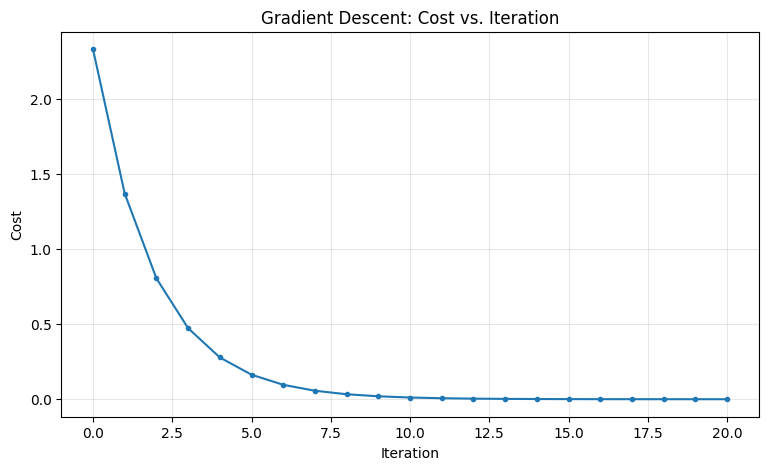

In [4]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["Iteration"],
    history["Cost"],
    marker="o",
    markersize=3
)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Gradient Descent: Cost vs. Iteration")
plt.grid(True, alpha=0.3)
plt.show()

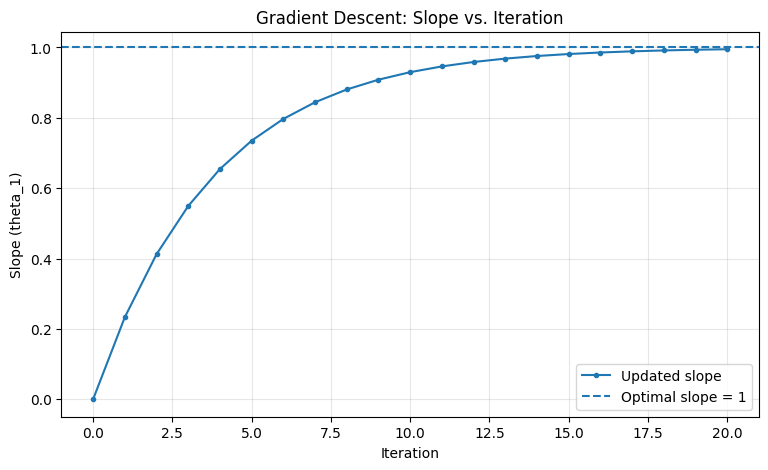

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["Iteration"],
    history["Slope"],
    marker="o",
    markersize=3,
    label="Updated slope"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Optimal slope = 1"
)

plt.xlabel("Iteration")
plt.ylabel("Slope (theta_1)")
plt.title("Gradient Descent: Slope vs. Iteration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Understanding the Learning Rate

The learning rate controls how far the parameter moves during each update.

$$
\theta_1^{\text{new}}
=
\theta_1^{\text{old}}
-
\alpha\frac{dJ}{d\theta_1}
$$

We will compare several learning rates using the same initial slope and number of iterations.

A small learning rate may converge slowly. A sufficiently large learning rate may reach the minimum faster, while an excessively large one can cause oscillation or divergence.

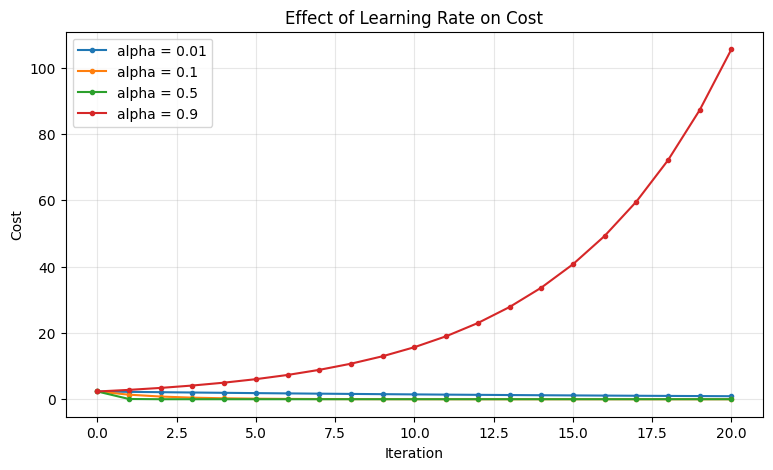

In [6]:
learning_rates = [0.01, 0.1, 0.5, 0.9]

plt.figure(figsize=(9, 5))

for alpha in learning_rates:
    _, rate_history = gradient_descent(
        initial_theta_1=0,
        learning_rate=alpha,
        iterations=20
    )

    plt.plot(
        rate_history["Iteration"],
        rate_history["Cost"],
        marker=".",
        label=f"alpha = {alpha}"
    )

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Effect of Learning Rate on Cost")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
# An intentionally excessive learning rate
unstable_slope, unstable_history = gradient_descent(
    initial_theta_1=0,
    learning_rate=1.0,
    iterations=10
)

unstable_history[["Iteration", "Slope", "Gradient", "Cost"]].round(4)

,Iteration,Slope,Gradient,Cost
0,0,0.0000,-2.3333,2.3333
1,1,2.3333,3.1111,4.1481
2,2,-0.7778,-4.1481,7.3745
3,3,3.3704,5.5309,13.1102
4,4,-2.1605,-7.3745,23.3070
5,5,5.2140,9.8326,41.4347
6,6,-4.6187,-13.1102,73.6617
7,7,8.4915,17.4803,130.9541
8,8,-8.9887,-23.3070,232.8073
9,9,14.3183,31.0760,413.8796


## 4. Understanding Convergence

Convergence occurs when the optimization process reaches its stopping condition or the updates become sufficiently small.

We can monitor:

- Cost change between iterations.
- Parameter change between iterations.
- Maximum iteration count.

A low cost or small update does not automatically prove that every possible optimization problem has reached its global minimum. In this example, however, the cost is a convex quadratic function with a known global minimum at $\theta_1=1$.

In [8]:
def gradient_descent_until_convergence(
    initial_theta_1,
    learning_rate,
    tolerance=1e-6,
    max_iterations=10_000
):
    theta_1 = float(initial_theta_1)
    history = []

    for iteration in range(max_iterations + 1):
        cost = compute_cost(
            data["x"],
            data["y"],
            theta_0=0,
            theta_1=theta_1
        )

        gradient = compute_gradient(theta_1)

        history.append({
            "Iteration": iteration,
            "Slope": theta_1,
            "Gradient": gradient,
            "Cost": cost
        })

        if abs(gradient) < tolerance:
            break

        new_theta_1 = theta_1 - learning_rate * gradient

        if abs(new_theta_1 - theta_1) < tolerance:
            theta_1 = new_theta_1
            break

        theta_1 = new_theta_1

    return theta_1, pd.DataFrame(history)


converged_slope, convergence_history = (
    gradient_descent_until_convergence(
        initial_theta_1=0,
        learning_rate=0.1
    )
)

print(f"Converged slope: {converged_slope:.8f}")
print(f"Final cost:      {convergence_history['Cost'].iloc[-1]:.10f}")
print(f"Iterations:      {len(convergence_history) - 1}")

Converged slope: 0.99999711
Final cost:      0.0000000000
Iterations:      47


## 5. Self-Check

1. What does the derivative tell us?
2. What is the purpose of the learning rate?
3. Why does a negative gradient increase the parameter?
4. What can happen when the learning rate is too large?
5. What is the global minimum in our simplified example?
6. Why must the gradient be recalculated after each update?
7. Does convergence always guarantee a global minimum?
8. Which values are fixed in this notebook, and which parameter is updated?

### Answers

1. The local rate and direction of change in cost.
2. It controls the size of each parameter update.
3. The update subtracts a negative gradient, increasing the parameter.
4. Updates may overshoot, oscillate, or diverge.
5. Slope = 1 and cost = 0.
6. The gradient changes as the parameter changes.
7. No. It depends on the optimization problem.
8. The intercept is fixed at zero; only the slope is updated.